# Explore sims
Hillas parameter distributions, image centroids, energies, multiplicities and reconstructed directions for a chosen
set of telescopes and cuts, from an already processed sim_telarray production (run `process_sims.ipynb` first). The
simulated counterpart of `analysis_tools/explore_events.ipynb`.

Everything is set in **Selection** below: pick a config, then override its telescopes or cuts there to compare
selections.

Camera coordinates are sim_telarray's, fixed to the alt-az mount: +x towards higher altitude, +y towards lower azimuth.

# Imports

In [1]:
import glob
from pathlib import Path

import numpy as np
import pandas as pd
from matplotlib import pyplot as plt

from heap import diagnostics as dg
from heap import events as ev
from heap import process_simulation as ps
from heap.parameterize import TAB10_COLORS
from heap.reconstruction import reconstruct_directions
from run_simulation import load_config

# Selection

In [2]:
CONFIG = Path("../configs/simulation.yaml") # relative to simulation_tools/; or a production's <output_dir>/slurm/<job>.yaml
cfg = load_config(CONFIG)

OUTPUT_DIR = cfg["paths"]["output_dir"]
NAME = cfg["production"]["name"]
TAG = cfg["sim_telarray"]["tag"]
SIMTEL_FILES = sorted(glob.glob(str(OUTPUT_DIR / "simtel" / TAG / f"{NAME}_run*.simtel.zst")))
if cfg["paths"]["processed_dir"] is None:
    raise ValueError(f"set paths.processed_dir in {CONFIG}: where processed sims go, outside the (maybe shared) output_dir")
PROCESSED_DIR = cfg["paths"]["processed_dir"] / NAME / TAG

# override any of these, e.g. TELESCOPES = ["T1", "T2", "T3"] or IMAGE_CUTS = {"width": ("value", 0.3)}
TELESCOPES = None # None = every telescope; "T<sim_telarray id>"
MIN_TEL = 2
MIN_NPIX = 3
IMAGE_CUTS = {} # {column: (mode, threshold)}, see heap.events.apply_cut()

# plotting
N_EVENTS = 4 # reconstructed events to display
PLOT_RADIUS = 3 # deg from the camera center for the direction histogram
ENERGY_BINS = np.logspace(0, 3, 16) # TeV

In [3]:
runs = ps.run_table(SIMTEL_FILES)
if TELESCOPES is None:
    TELESCOPES = [f"T{tel_id}" for tel_id in runs.iloc[0].tel_id]
COLORS = {name: TAB10_COLORS[i] for i, name in enumerate(sorted(TELESCOPES))}
print(f"{NAME} ({TAG}): {len(runs)} runs, {(runs.n_showers * runs.n_use).sum()} events simulated")
print(f"telescopes {TELESCOPES}, cuts: min_tel {MIN_TEL}, min_npix {MIN_NPIX}, image cuts {IMAGE_CUTS}")

gamma_pointlike (v1): 1000 runs, 500000 events simulated
telescopes ['T1', 'T2', 'T3', 'T4', 'T5', 'T6', 'T7'], cuts: min_tel 2, min_npix 3, image cuts {}


# Events
Images of `TELESCOPES` matched into array events by `Run` and `EventID` (`heap.process_simulation.load_events()`),
then the cuts (`heap.events.apply_cuts()`).

In [4]:
df, showers = ps.load_events(PROCESSED_DIR, NAME, runs, TELESCOPES)
array = ev.apply_cuts(df, min_tel=MIN_TEL, min_npix=MIN_NPIX, telescopes=TELESCOPES, cuts=IMAGE_CUTS)
triggered = showers[showers.Event.isin(df.Event)]
after_cuts = showers[showers.Event.isin(array.Event)]
print(f"{df.Event.nunique()} events ({len(df)} images) before cuts, {array.Event.nunique()} events ({len(array)} images) after")

29636 events (36728 images) before cuts, 5493 events (12574 images) after


In [5]:
# events per telescope combination before cuts, and how many of them still have MIN_TEL+ images after cuts
combo = df.groupby("Event").Telescope.agg(lambda t: " + ".join(sorted(t)))
n_images = array.Event.value_counts()
kept = combo.index.isin(n_images[n_images >= MIN_TEL].index)
pd.DataFrame({"before cuts": combo.value_counts(), "after cuts": combo[kept].value_counts()}).fillna(0).astype(int)

,before cuts,after cuts
Telescope,,
T1,2505,0
T1 + T2,77,77
T1 + T2 + T3,336,336
T1 + T2 + T3 + T5,16,16
T1 + T2 + T3 + T5 + T6 + T7,1,1
T1 + T2 + T3 + T5 + T7,5,5
T1 + T2 + T3 + T6,1,1
T1 + T2 + T3 + T6 + T7,30,30
T1 + T2 + T3 + T7,60,60


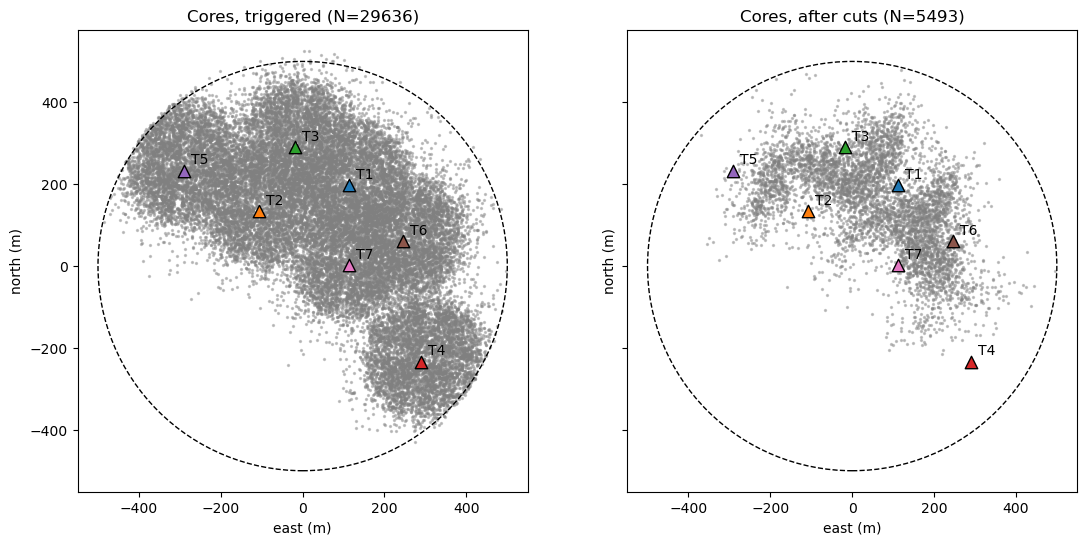

In [6]:
ps.plot_cores(runs, {"triggered": triggered, "after cuts": after_cuts}, colors=COLORS)
plt.show()

# Energy and multiplicity
Energies of the simulated, triggered (any telescope of `TELESCOPES` with an image) and kept (after cuts) events, then
the number of telescopes per event. The simulated counts are the power law of `heap.read_simtel.read_run_header()`,
over every run.

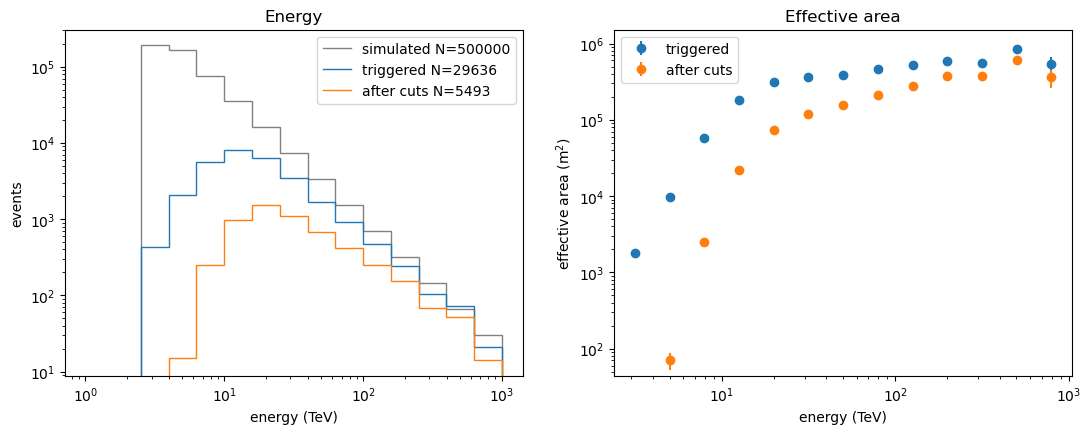

In [7]:
ps.plot_energies(runs, {"triggered": triggered, "after cuts": after_cuts}, ENERGY_BINS)
plt.show()

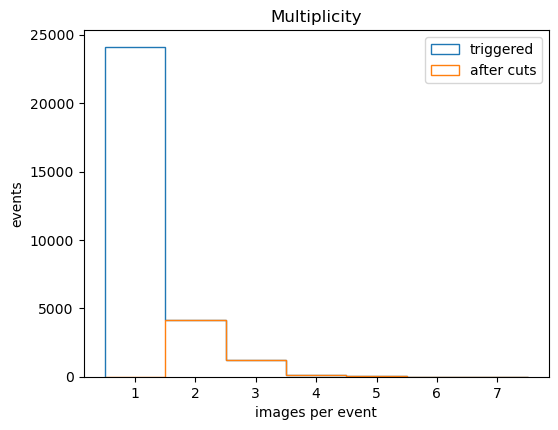

In [8]:
ps.plot_multiplicity({"triggered": df, "after cuts": array}, len(TELESCOPES))
plt.show()

# Hillas parameters
One line per telescope, all telescopes pooled filled in grey. `distance` and `alpha` are from the camera center
(`process_simulation()`'s default `x`, `y`), the source position only without a wobble.

/home/korzoun/.conda/envs/panoseti/lib/python3.11/site-packages/pandas/core/arraylike.py:399: RuntimeWarning: divide by zero encountered in log10
  result = getattr(ufunc, method)(*inputs, **kwargs)


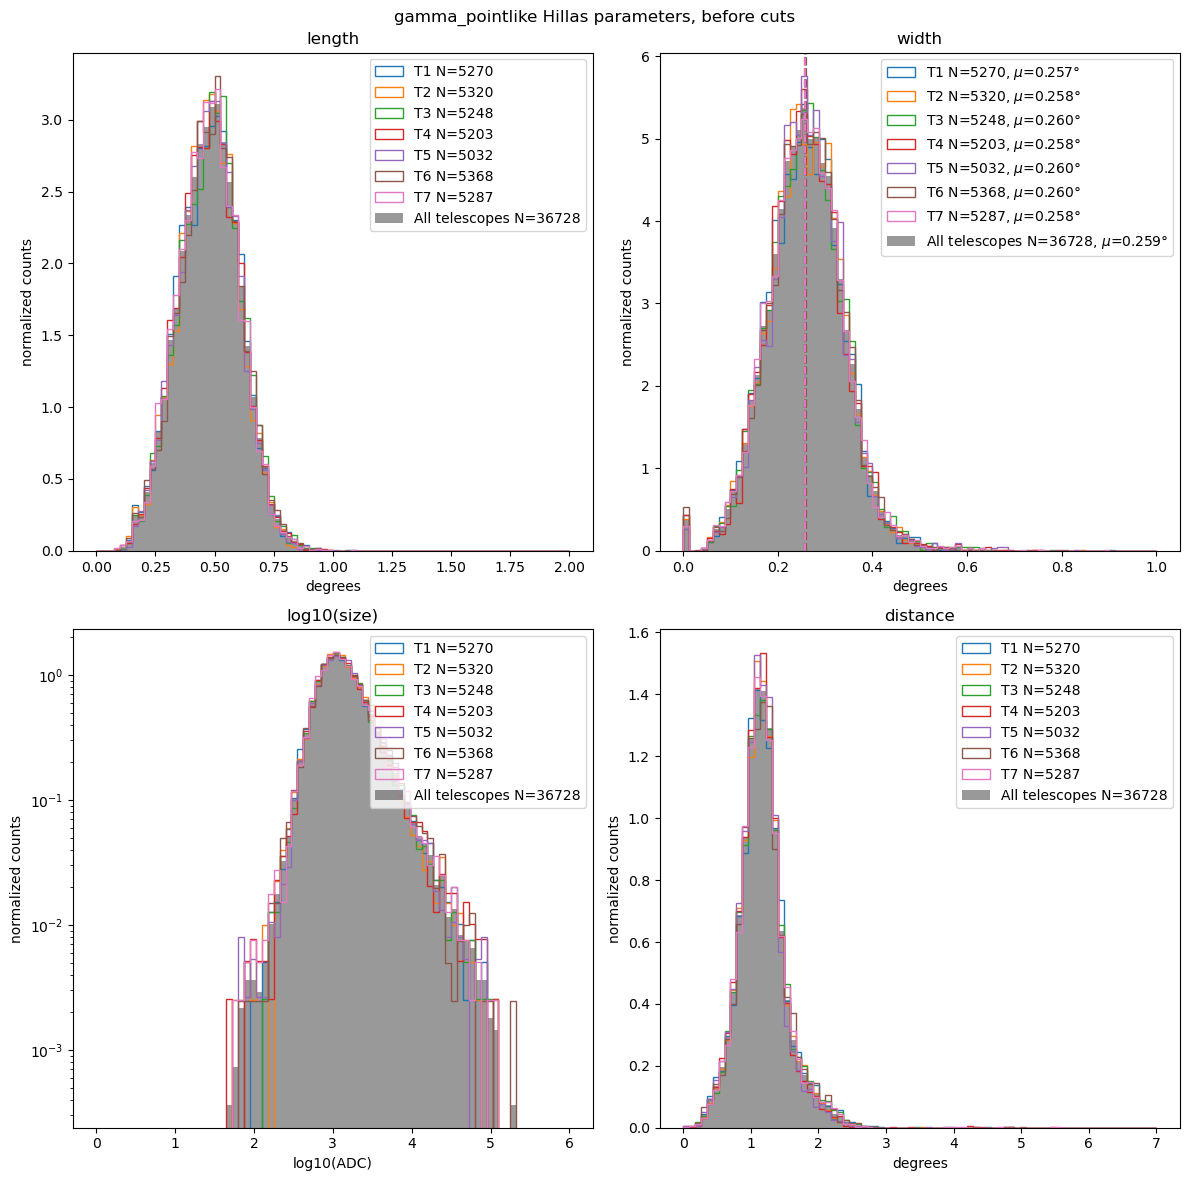

In [9]:
ev.plot_hillas(df, f"{NAME} Hillas parameters, before cuts", colors=COLORS)
plt.show()

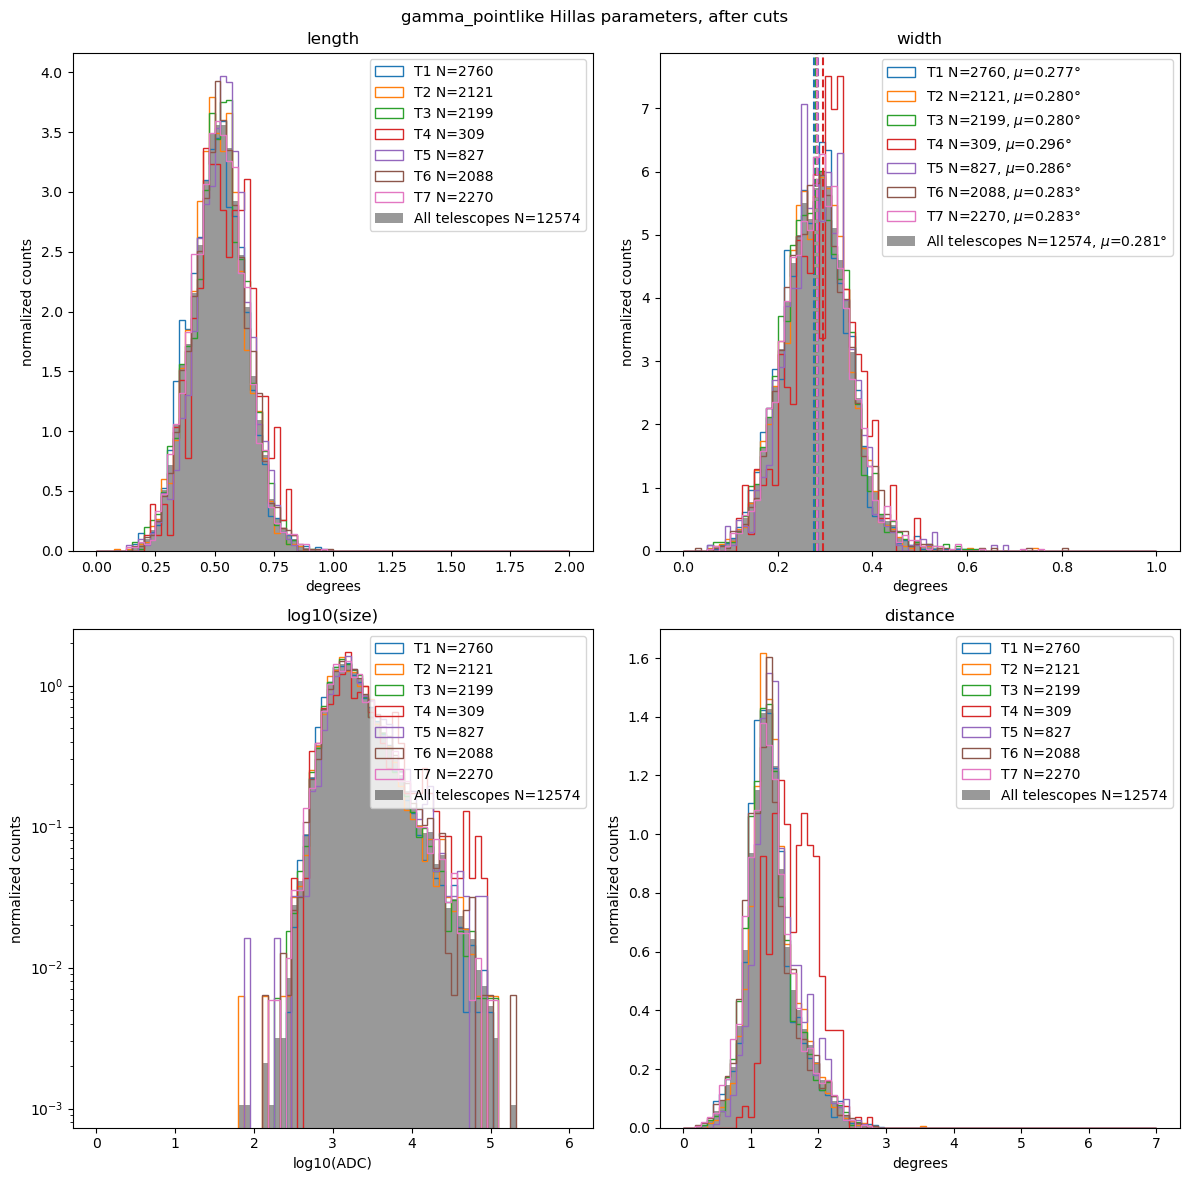

In [10]:
ev.plot_hillas(array, f"{NAME} Hillas parameters, after cuts", colors=COLORS)
plt.show()

In [11]:
array.groupby("Telescope")[["N_pix", "size", "length", "width", "distance", "alpha"]].describe().T

Telescope                  T1             T2             T3            T4  \
N_pix    count    2760.000000    2121.000000    2199.000000    309.000000   
         mean       25.253623      25.643093      25.878581     31.601942   
         std        16.015651      16.357141      16.797035     22.595830   
         min         3.000000       3.000000       3.000000      6.000000   
         25%        16.000000      16.000000      16.000000     18.000000   
         50%        22.000000      22.000000      22.000000     24.000000   
         75%        30.000000      30.000000      30.000000     38.000000   
         max       216.000000     279.000000     220.000000    168.000000   
size     count    2760.000000    2121.000000    2199.000000    309.000000   
         mean     2917.872977    3065.412232    3019.578441   5086.708999   
         std      5383.113747    5925.053122    5974.793713  10143.162345   
         min       287.338461      68.212780     198.600573    340.523227   
         25%      1074.184205    1108.833681    1103.411693   1262.443599   
         50%      1618.381048    1661.942434    1641.342215   1933.464099   
         75%      2781.637596    2851.361296    2693.058948   3952.045005   
         max    105004.118659  111773.795600  122017.151099  87137.272548   
length   count    2760.000000    2121.000000    2199.000000    309.000000   
         mean        0.508420       0.511881       0.516353      0.542807   
         std         0.115704       0.109235       0.114172      0.120183   
         min         0.144517       0.096209       0.150239      0.211227   
         25%         0.429301       0.439385       0.445047      0.464275   
         50%         0.509737       0.513346       0.521431      0.534229   
         75%         0.589235       0.584142       0.595150      0.626818   
         max         0.958147       0.872834       0.903071      0.839078   
width    count    2760.000000    2121.000000    2199.000000    309.000000   
         mean        0.276949       0.280188       0.279730      0.296361   
         std         0.069122       0.068698       0.071641      0.068607   
         min         0.052826       0.060805       0.061776      0.115628   
         25%         0.230423       0.234792       0.232004      0.251157   
         50%         0.278665       0.281931       0.278476      0.302963   
         75%         0.321482       0.325141       0.325613      0.338035   
         max         0.626463       0.744909       0.616738      0.497045   
distance count    2760.000000    2121.000000    2199.000000    309.000000   
         mean        1.289931       1.337071       1.295032      1.656064   
         std         0.351457       0.342599       0.358021      0.338302   
         min         0.328765       0.353058       0.265188      0.836885   
         25%         1.067885       1.127052       1.062479      1.393442   
         50%         1.246096       1.283349       1.249730      1.652351   
         75%         1.453340       1.510164       1.454730      1.905300   
         max         2.906785       3.544919       2.706426      2.746754   
alpha    count    2760.000000    2121.000000    2199.000000    309.000000   
         mean       10.346559      10.432501      10.102133      8.460629   
         std        11.967535      12.453840      12.060338      9.403392   
         min         0.002193       0.000101       0.001639      0.034643   
         25%         3.012266       2.946081       2.887349      2.508740   
         50%         6.591654       6.794016       6.454190      6.339472   
         75%        13.115651      12.967374      12.554051     10.242229   
         max        89.450570      89.841823      88.921138     69.774517   

Telescope                 T5             T6             T7  
N_pix    count    827.000000    2088.000000    2270.000000  
         mean      28.564692      27.098659      26.544053  
         std       19.086057      18.675471

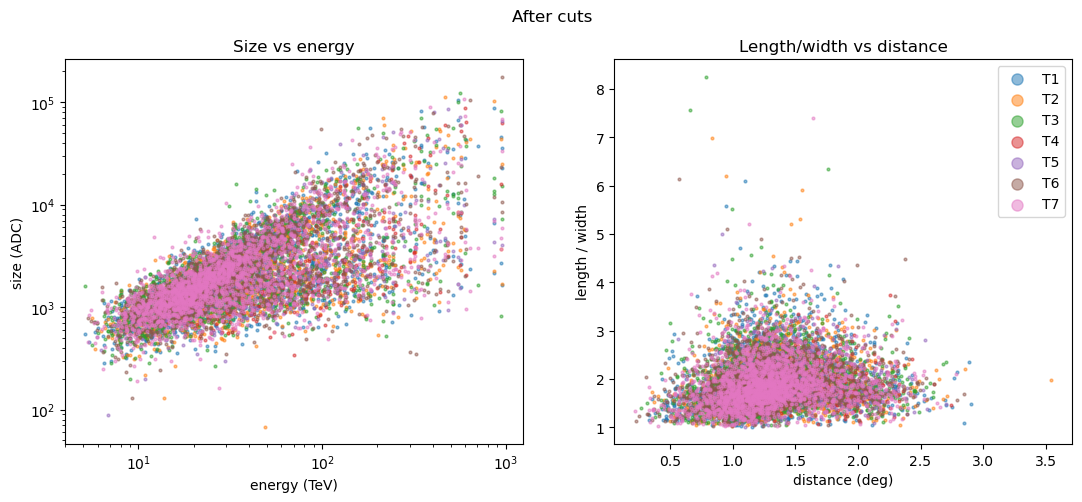

In [12]:
ps.plot_image_params(array, showers, "After cuts", colors=COLORS)
plt.show()

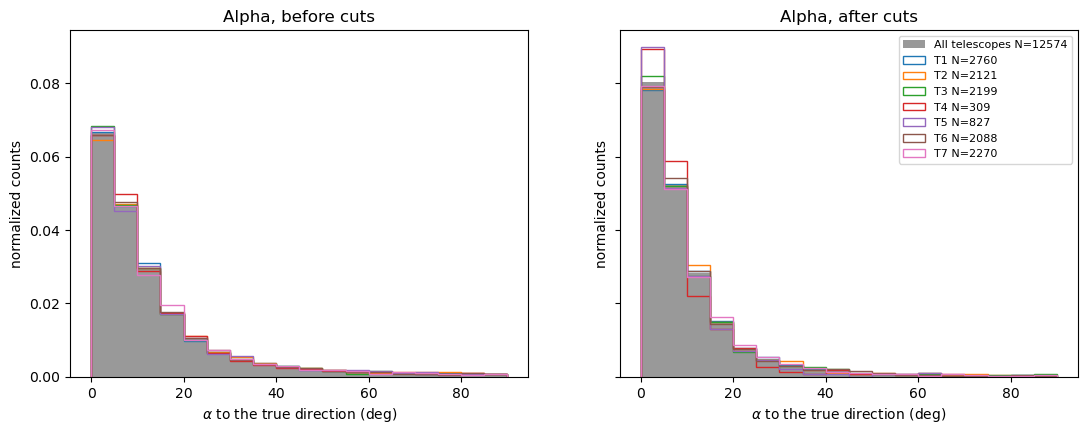

In [13]:
# alpha to the true direction (the Hillas alpha is from the camera center)
ps.plot_alpha({"before cuts": df, "after cuts": array}, showers, colors=COLORS)
plt.show()

# Image centroids
Centroids (`x_c`, `y_c`) in camera coordinates, one bin per pixel.

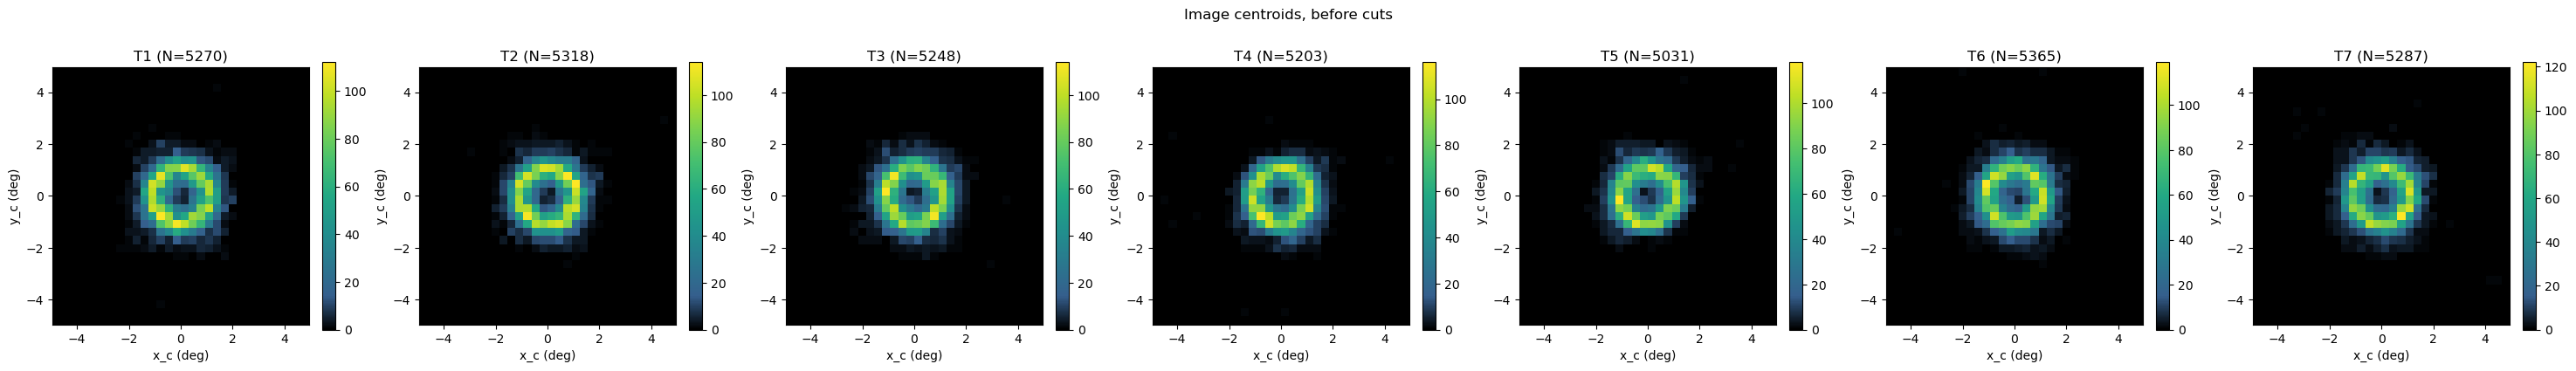

In [14]:
dg.plot_centroids(df, "Image centroids, before cuts", telescopes=TELESCOPES)
plt.show()

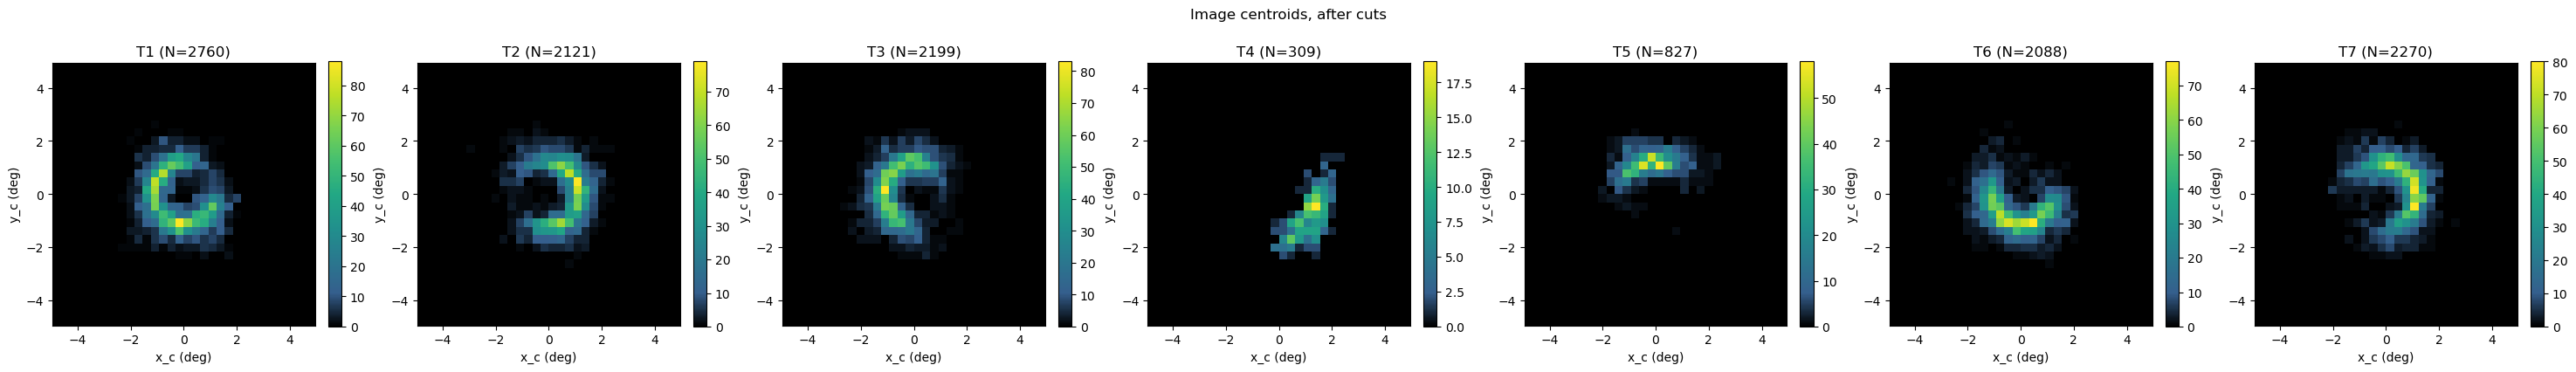

In [15]:
dg.plot_centroids(array, "Image centroids, after cuts", telescopes=TELESCOPES)
plt.show()

# Reconstruction
Arrival directions (`heap.reconstruction`) against the primary's true direction (`true_x`, `true_y`, see
`heap.process_simulation.camera_position()`).

In [16]:
directions = reconstruct_directions(array).merge(showers[["Event", "energy", "true_x", "true_y"]], on="Event")
directions["theta2"] = (directions.Xoffset - directions.true_x)**2 + (directions.Yoffset - directions.true_y)**2
print(f"{len(directions)} reconstructed events, 68% containment {np.sqrt(directions.theta2.quantile(0.68)):.3f} deg")

5493 reconstructed events, 68% containment 0.525 deg


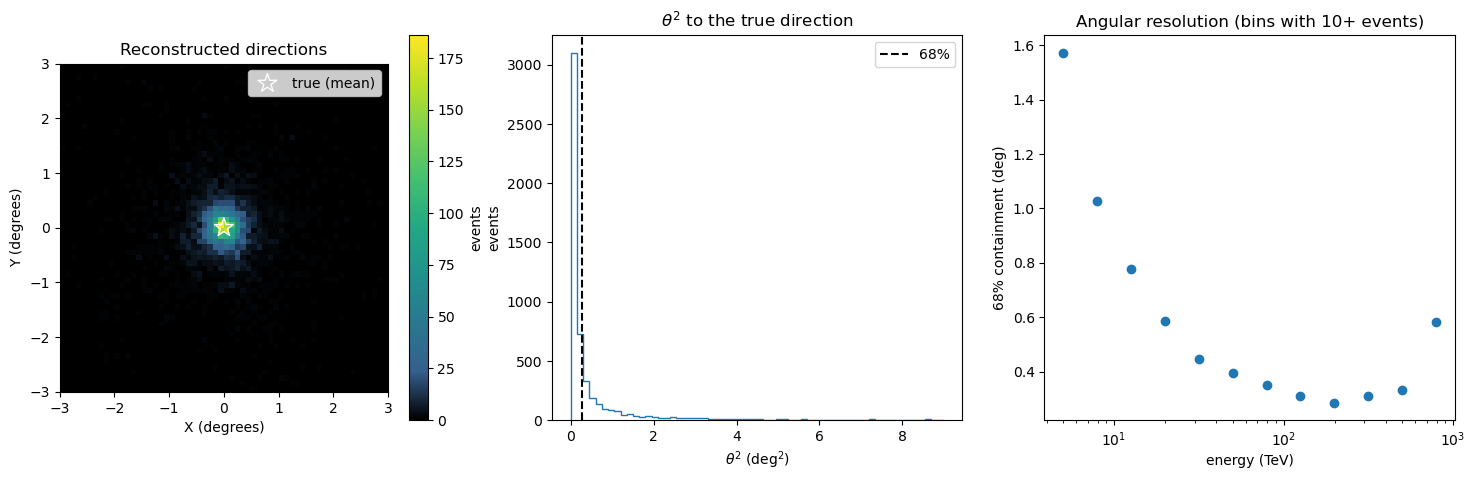

In [17]:
ps.plot_directions(directions, ENERGY_BINS, radius=PLOT_RADIUS)
plt.show()

## Event display
Each cleaned image of an event, then all its Hillas ellipses together, with the reconstructed (x) and true (star)
directions. Run the cell again for other events.

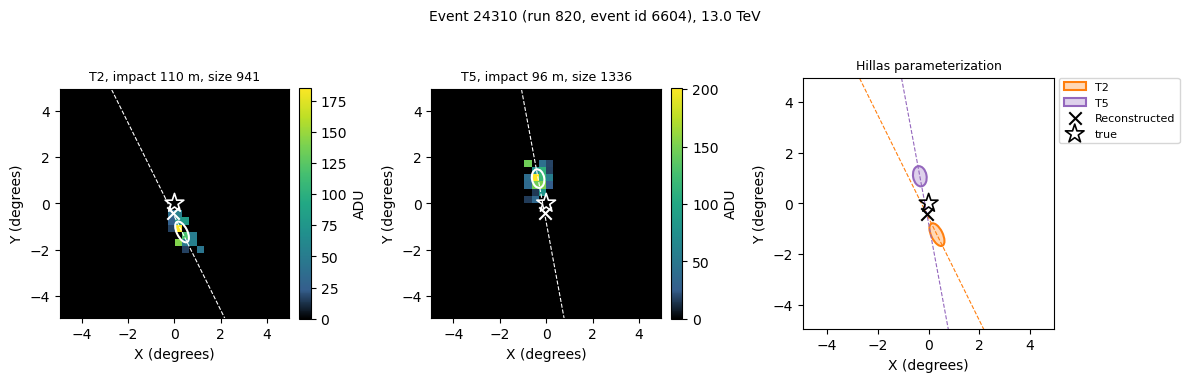

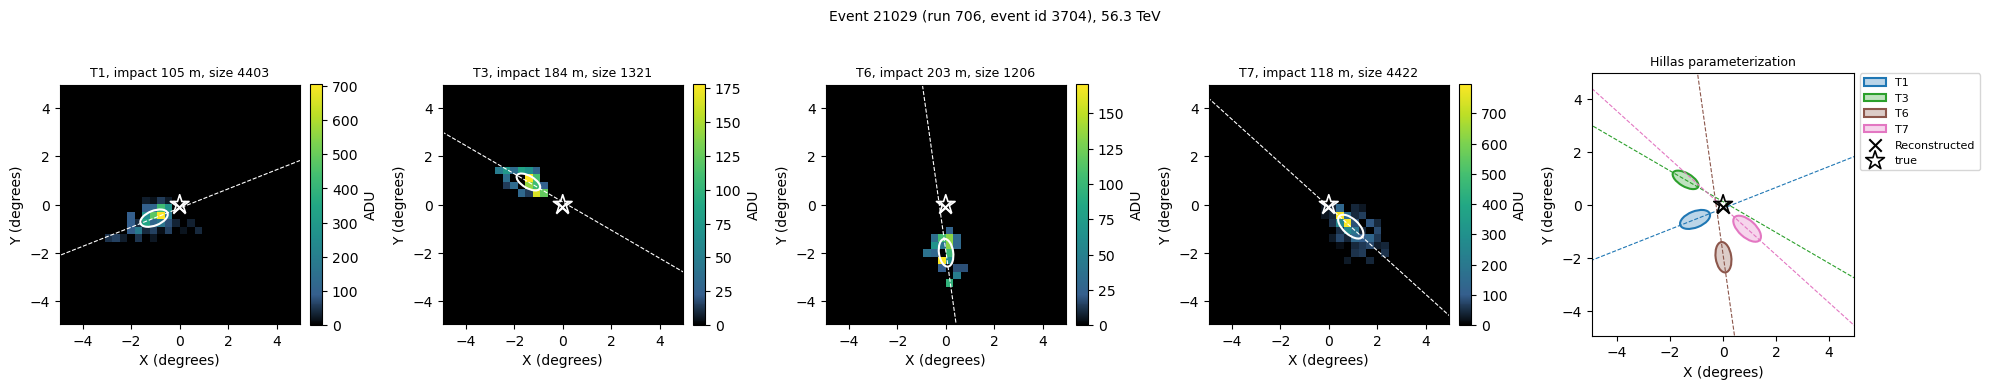

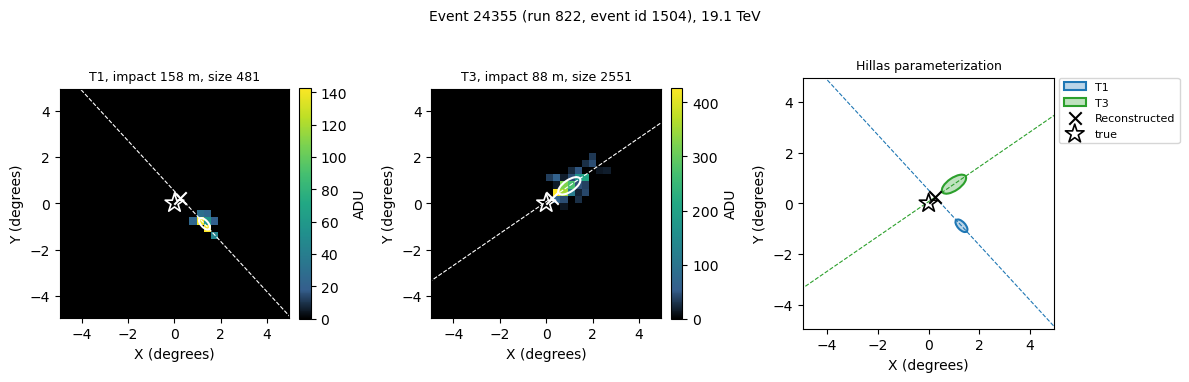

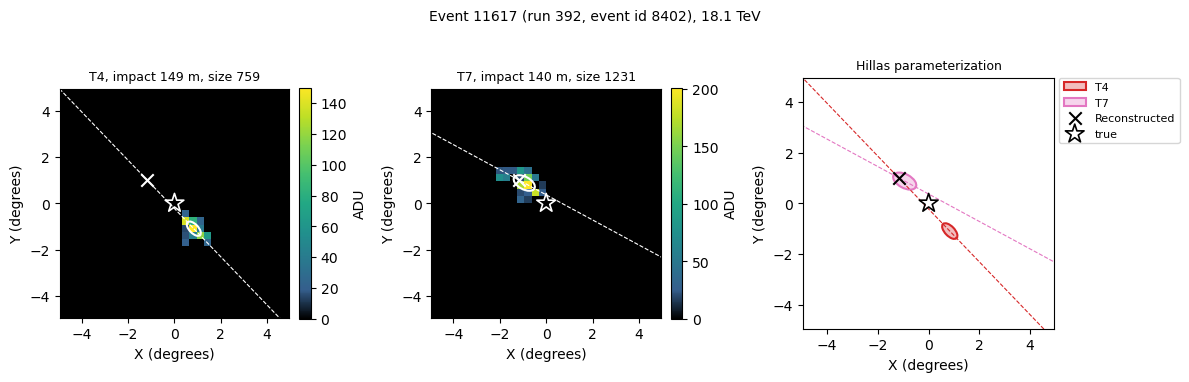

In [18]:
for e in np.random.default_rng().choice(directions.Event, size=min(N_EVENTS, len(directions)), replace=False):
    ps.plot_event(
        array[array.Event == e], directions[directions.Event == e].iloc[0], showers.set_index("Event").loc[e],
        PROCESSED_DIR, NAME, colors=COLORS,
    )
    plt.show()